<a href="https://colab.research.google.com/github/SATYA012904/Disease-Symptom-Pattern-Discovery/blob/main/Copy_of_Road_Scene_Semantic_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)

print("\nAvailable Devices:")
print("CPU:", tf.config.list_physical_devices("CPU"))
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
NumPy: 2.4.6
OpenCV: 4.14.0

Available Devices:
CPU: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/Road_Segmentation_Dataset"

print("Files in dataset folder:")

for file in os.listdir(dataset_path):
    file_path = os.path.join(dataset_path, file)
    size_gb = os.path.getsize(file_path) / (1024 ** 3)

    print(f"{file} : {size_gb:.2f} GB")


Files in dataset folder:
gtFine_trainvaltest.zip : 0.24 GB
leftImg8bit_trainvaltest.zip : 10.80 GB


In [ ]:
import shutil

total, used, free = shutil.disk_usage("/content")

print(f"Total storage: {total / (1024**3):.2f} GB")
print(f"Used storage: {used / (1024**3):.2f} GB")
print(f"Free storage: {free / (1024**3):.2f} GB")


Total storage: 112.64 GB
Used storage: 0.08 GB
Free storage: 112.54 GB


In [ ]:
import zipfile
import os

dataset_path = "/content/drive/MyDrive/Road_Segmentation_Dataset"
extract_path = "/content/cityscapes"

os.makedirs(extract_path, exist_ok=True)

image_zip = os.path.join(
    dataset_path, "leftImg8bit_trainvaltest.zip"
)

with zipfile.ZipFile(image_zip, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Original images extracted successfully!")


Original images extracted successfully!


In [ ]:
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)

    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")


cityscapes/
  leftImg8bit/
    val/
      munster/
      frankfurt/
      lindau/
    test/
      bielefeld/
      mainz/
      leverkusen/
      berlin/
      bonn/
      munich/
    train/
      darmstadt/
      tubingen/
      monchengladbach/
      ulm/
      hanover/
      erfurt/
      weimar/
      bochum/
      jena/
      stuttgart/
      krefeld/
      strasbourg/
      hamburg/
      aachen/
      dusseldorf/
      zurich/
      bremen/
      cologne/


In [ ]:
import os

extract_path = "/content/cityscapes"

print("Main folders:")
print(os.listdir(extract_path))

print("\nAnnotation folder exists:",
      os.path.exists(os.path.join(extract_path, "gtFine")))


Main folders:
['leftImg8bit', 'README', 'license.txt']

Annotation folder exists: False


In [ ]:
import zipfile
import os

annotation_zip = "/content/drive/MyDrive/Road_Segmentation_Dataset/gtFine_trainvaltest.zip"

print("File exists:", os.path.exists(annotation_zip))
print("File size:", round(os.path.getsize(annotation_zip) / (1024**2), 2), "MB")

with zipfile.ZipFile(annotation_zip, "r") as zip_ref:
    print("\nFirst 20 entries inside ZIP:")

    for name in zip_ref.namelist()[:20]:
        print(name)

    print("\nTotal entries:", len(zip_ref.namelist()))
    print("ZIP integrity:", zip_ref.testzip())


File exists: True
File size: 240.87 MB

First 20 entries inside ZIP:
README
license.txt
gtFine/train/
gtFine/train/jena/
gtFine/train/jena/jena_000020_000019_gtFine_labelIds.png
gtFine/train/jena/jena_000092_000019_gtFine_polygons.json
gtFine/train/jena/jena_000061_000019_gtFine_polygons.json
gtFine/train/jena/jena_000104_000019_gtFine_polygons.json
gtFine/train/jena/jena_000064_000019_gtFine_labelIds.png
gtFine/train/jena/jena_000015_000019_gtFine_instanceIds.png
gtFine/train/jena/jena_000041_000019_gtFine_labelIds.png
gtFine/train/jena/jena_000097_000019_gtFine_labelIds.png
gtFine/train/jena/jena_000071_000019_gtFine_labelIds.png
gtFine/train/jena/jena_000099_000019_gtFine_color.png
gtFine/train/jena/jena_000004_000019_gtFine_instanceIds.png
gtFine/train/jena/jena_000059_000019_gtFine_polygons.json
gtFine/train/jena/jena_000028_000019_gtFine_labelIds.png
gtFine/train/jena/jena_000003_000019_gtFine_polygons.json
gtFine/train/jena/jena_000083_000019_gtFine_color.png
gtFine/train/jena/j

In [ ]:
import zipfile
import os

annotation_zip = "/content/drive/MyDrive/Road_Segmentation_Dataset/gtFine_trainvaltest.zip"
extract_path = "/content/cityscapes"

with zipfile.ZipFile(annotation_zip, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")

# Verify folders
gt_path = os.path.join(extract_path, "gtFine")

print("\nAnnotation folder exists:", os.path.exists(gt_path))
print("Available folders:", os.listdir(gt_path))

print("\nTraining cities:", len(os.listdir(os.path.join(gt_path, "train"))))
print("Validation cities:", len(os.listdir(os.path.join(gt_path, "val"))))


Extraction completed!

Annotation folder exists: True
Available folders: ['val', 'test', 'train']

Training cities: 18
Validation cities: 3


In [ ]:
import os
import glob

BASE_PATH = "/content/cityscapes"

IMAGE_PATH = os.path.join(BASE_PATH, "leftImg8bit")
MASK_PATH = os.path.join(BASE_PATH, "gtFine")

# Get all training images
train_images = sorted(
    glob.glob(
        os.path.join(IMAGE_PATH, "train", "*", "*_leftImg8bit.png")
    )
)

# Get all training masks
train_masks = sorted(
    glob.glob(
        os.path.join(MASK_PATH, "train", "*", "*_gtFine_labelIds.png")
    )
)

print("Training Images:", len(train_images))
print("Training Masks:", len(train_masks))

print("\nSample Image:")
print(train_images[0])

print("\nSample Mask:")
print(train_masks[0])

Training Images: 2975
Training Masks: 2975

Sample Image:
/content/cityscapes/leftImg8bit/train/aachen/aachen_000000_000019_leftImg8bit.png

Sample Mask:
/content/cityscapes/gtFine/train/aachen/aachen_000000_000019_gtFine_labelIds.png


In [ ]:
import cv2

image = cv2.imread(train_images[0])
mask = cv2.imread(train_masks[0], cv2.IMREAD_UNCHANGED)

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Mask data type:", mask.dtype)

print("\nUnique label IDs:")
print(sorted(set(mask.flatten()))[:50])

Image shape: (1024, 2048, 3)
Mask shape: (1024, 2048)
Mask data type: uint8

Unique label IDs:
[np.uint8(0), np.uint8(1), np.uint8(3), np.uint8(4), np.uint8(7), np.uint8(8), np.uint8(11), np.uint8(17), np.uint8(20), np.uint8(21), np.uint8(22), np.uint8(23), np.uint8(24), np.uint8(25), np.uint8(26), np.uint8(33)]


In [ ]:
%pip install -q opencv-python-headless matplotlib pandas scikit-learn streamlit pillow tqdm seaborn

# ==========================================
# IMPORT LIBRARIES
# ==========================================

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Numerical and Data Processing
import numpy as np
import pandas as pd

# Image Processing
import cv2
from PIL import Image

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Metrics
from sklearn.metrics import confusion_matrix

# File and Directory Handling
import os
import glob
import shutil
import zipfile
import json
import random
from pathlib import Path

# Progress Monitoring
from tqdm.auto import tqdm

# System Information
import sys
import time


In [ ]:
import numpy as np

NUM_CLASSES = 19
IGNORE_LABEL = 255

label_mapping = {
    7: 0, 8: 1, 11: 2, 12: 3, 13: 4,
    17: 5, 19: 6, 20: 7, 21: 8, 22: 9,
    23: 10, 24: 11, 25: 12, 26: 13,
    27: 14, 28: 15, 31: 16, 32: 17, 33: 18
}

id_to_trainid = np.full(256, IGNORE_LABEL, dtype=np.uint8)

for original_id, train_id in label_mapping.items():
    id_to_trainid[original_id] = train_id

print("Label mapping initialized successfully!")

Label mapping initialized successfully!


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread(train_images[0])
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

original_mask = cv2.imread(
    train_masks[0],
    cv2.IMREAD_UNCHANGED
)

train_mask = id_to_trainid[original_mask]

print("Original IDs:", np.unique(original_mask))
print("Training IDs:", np.unique(train_mask))
print("Converted mask shape:", train_mask.shape)

Original IDs: [ 0  1  3  4  7  8 11 17 20 21 22 23 24 25 26 33]
Training IDs: [  0   1   2   5   7   8   9  10  11  12  13  18 255]
Converted mask shape: (1024, 2048)


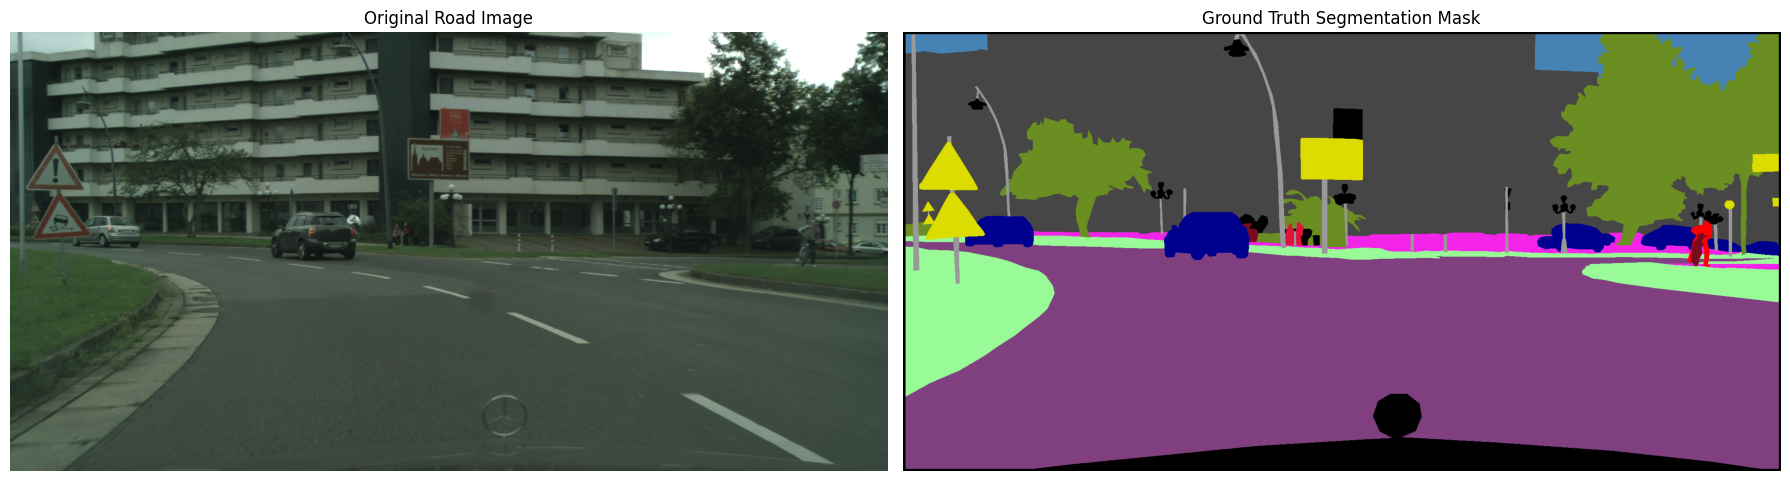

In [ ]:
# Cityscapes colors for the 19 training classes
cityscapes_colors = [
    (128, 64, 128),   # Road
    (244, 35, 232),   # Sidewalk
    (70, 70, 70),     # Building
    (102, 102, 156),  # Wall
    (190, 153, 153),  # Fence
    (153, 153, 153),  # Pole
    (250, 170, 30),   # Traffic Light
    (220, 220, 0),    # Traffic Sign
    (107, 142, 35),   # Vegetation
    (152, 251, 152),  # Terrain
    (70, 130, 180),   # Sky
    (220, 20, 60),    # Person
    (255, 0, 0),      # Rider
    (0, 0, 142),      # Car
    (0, 0, 70),       # Truck
    (0, 60, 100),     # Bus
    (0, 80, 100),     # Train
    (0, 0, 230),     # Motorcycle
    (119, 11, 32)     # Bicycle
]

# Black color for ignored pixels
color_table = np.array([(0, 0, 0)] + cityscapes_colors, dtype=np.uint8)

# Shift valid training IDs from 0–18 to 1–19.
# Ignore label 255 is displayed as black (index 0).
display_mask = np.where(
    train_mask == IGNORE_LABEL,
    0,
    train_mask + 1
)

rgb_mask = color_table[display_mask]

# Display image and mask
plt.figure(figsize=(18, 7))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Road Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rgb_mask)
plt.title("Ground Truth Segmentation Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Target image dimensions
IMG_HEIGHT = 512
IMG_WIDTH = 1024

NUM_CLASSES = 19
IGNORE_LABEL = 255

def preprocess_pair(image_path, mask_path):

    # Read original image
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Read original annotation mask
    mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)

    # Convert original label IDs into training IDs
    mask = id_to_trainid[mask]

    # Resize image using bilinear interpolation
    image = cv2.resize(
        image,
        (IMG_WIDTH, IMG_HEIGHT),
        interpolation=cv2.INTER_LINEAR
    )

    # Resize mask using nearest-neighbor interpolation
    mask = cv2.resize(
        mask,
        (IMG_WIDTH, IMG_HEIGHT),
        interpolation=cv2.INTER_NEAREST
    )

    # Normalize image pixels from 0-255 to 0-1
    image = image.astype(np.float32) / 255.0

    # Keep mask values as integer class IDs
    mask = mask.astype(np.int32)

    return image, mask

In [ ]:
sample_image, sample_mask = preprocess_pair(
    train_images[0],
    train_masks[0]
)

print("Processed Image Shape:", sample_image.shape)
print("Processed Mask Shape:", sample_mask.shape)

print("Image Data Type:", sample_image.dtype)
print("Mask Data Type:", sample_mask.dtype)

print("Image Pixel Range:",
      sample_image.min(), "to", sample_image.max())

print("Training Mask IDs:", np.unique(sample_mask))

Processed Image Shape: (512, 1024, 3)
Processed Mask Shape: (512, 1024)
Image Data Type: float32
Mask Data Type: int32
Image Pixel Range: 0.05490196 to 1.0
Training Mask IDs: [  0   1   2   5   7   8   9  10  11  12  13  18 255]


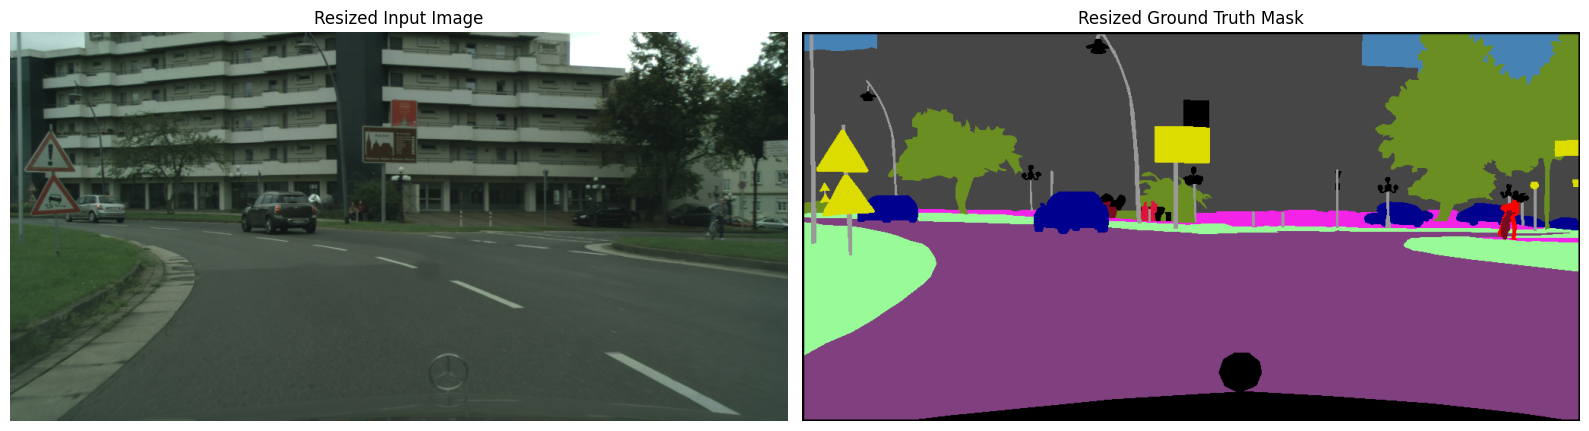

In [ ]:
display_mask = np.where(
    sample_mask == IGNORE_LABEL,
    0,
    sample_mask + 1
)

rgb_mask = color_table[display_mask]

plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.imshow(sample_image)
plt.title("Resized Input Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rgb_mask)
plt.title("Resized Ground Truth Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Training paths
train_images = sorted(
    glob.glob(os.path.join(IMAGE_PATH, "train", "*", "*_leftImg8bit.png"))
)

train_masks = sorted(
    glob.glob(os.path.join(MASK_PATH, "train", "*", "*_gtFine_labelIds.png"))
)

# Validation paths
val_images = sorted(
    glob.glob(os.path.join(IMAGE_PATH, "val", "*", "*_leftImg8bit.png"))
)

val_masks = sorted(
    glob.glob(os.path.join(MASK_PATH, "val", "*", "*_gtFine_labelIds.png"))
)

print("Training pairs:", len(train_images), len(train_masks))
print("Validation pairs:", len(val_images), len(val_masks))

Training pairs: 2975 2975
Validation pairs: 500 500


In [ ]:
# TensorFlow constants
IMG_HEIGHT = 512
IMG_WIDTH = 1024
BATCH_SIZE = 4

label_lookup = tf.constant(id_to_trainid, dtype=tf.uint8)

def load_and_preprocess(image_path, mask_path, training=False):

    # Read image
    image = tf.io.read_file(image_path)
    image = tf.image.decode_png(image, channels=3)

    # Read annotation mask
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH],
        method="bilinear"
    )

    # Resize mask using nearest neighbor
    mask = tf.image.resize(
        mask,
        [IMG_HEIGHT, IMG_WIDTH],
        method="nearest"
    )

    # Convert image to float and normalize
    image = tf.cast(image, tf.float32) / 255.0

    # Convert original IDs to training IDs
    mask = tf.cast(mask, tf.uint8)
    mask = tf.gather(label_lookup, mask)
    mask = tf.squeeze(mask, axis=-1)

    # Apply the same horizontal flip to image and mask
    if training:
        should_flip = tf.random.uniform(()) > 0.5

        image, mask = tf.cond(
            should_flip,
            lambda: (
                tf.image.flip_left_right(image),
                tf.image.flip_left_right(mask[..., tf.newaxis])[..., 0]
            ),
            lambda: (image, mask)
        )

    return image, tf.cast(mask, tf.int32)

In [ ]:
# Training paths
train_images = sorted(
    glob.glob(os.path.join(IMAGE_PATH, "train", "*", "*_leftImg8bit.png"))
)

train_masks = sorted(
    glob.glob(os.path.join(MASK_PATH, "train", "*", "*_gtFine_labelIds.png"))
)

# Validation paths
val_images = sorted(
    glob.glob(os.path.join(IMAGE_PATH, "val", "*", "*_leftImg8bit.png"))
)

val_masks = sorted(
    glob.glob(os.path.join(MASK_PATH, "val", "*", "*_gtFine_labelIds.png"))
)

print("Training pairs:", len(train_images), len(train_masks))
print("Validation pairs:", len(val_images), len(val_masks))

Training pairs: 2975 2975
Validation pairs: 500 500


In [ ]:
# TensorFlow constants
IMG_HEIGHT = 512
IMG_WIDTH = 1024
BATCH_SIZE = 4

label_lookup = tf.constant(id_to_trainid, dtype=tf.uint8)

def load_and_preprocess(image_path, mask_path, training=False):

    # Read image
    image = tf.io.read_file(image_path)
    image = tf.image.decode_png(image, channels=3)

    # Read annotation mask
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH],
        method="bilinear"
    )

    # Resize mask using nearest neighbor
    mask = tf.image.resize(
        mask,
        [IMG_HEIGHT, IMG_WIDTH],
        method="nearest"
    )

    # Convert image to float and normalize
    image = tf.cast(image, tf.float32) / 255.0

    # Convert original IDs to training IDs
    mask = tf.cast(mask, tf.uint8)
    mask = tf.gather(label_lookup, mask)
    mask = tf.squeeze(mask, axis=-1)

    # Apply the same horizontal flip to image and mask
    if training:
        should_flip = tf.random.uniform(()) > 0.5

        image, mask = tf.cond(
            should_flip,
            lambda: (
                tf.image.flip_left_right(image),
                tf.image.flip_left_right(mask[..., tf.newaxis])[..., 0]
            ),
            lambda: (image, mask)
        )

    return image, tf.cast(mask, tf.int32)

In [ ]:
# Redefining the preprocess function with the uint8 -> int32 index casting fix for tf.gather
def load_and_preprocess(image_path, mask_path, training=False):
    # Read image
    image = tf.io.read_file(image_path)
    image = tf.image.decode_png(image, channels=3)

    # Read annotation mask
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH],
        method="bilinear"
    )

    # Resize mask using nearest neighbor
    mask = tf.image.resize(
        mask,
        [IMG_HEIGHT, IMG_WIDTH],
        method="nearest"
    )

    # Convert image to float and normalize
    # Apply MobileNetV2 ImageNet preprocessing: [0, 255] -> [-1, 1]
    image = tf.cast(image, tf.float32)
    image = keras.applications.mobilenet_v2.preprocess_input(image)

    # Convert original IDs to training IDs
    # FIX: Cast the mask to tf.int32 so that tf.gather can use it as indices
    mask = tf.cast(mask, tf.int32)
    mask = tf.gather(label_lookup, mask)
    mask = tf.squeeze(mask, axis=-1)

    # Apply the same horizontal flip to image and mask
    if training:
        should_flip = tf.random.uniform(()) > 0.5

        image, mask = tf.cond(
            should_flip,
            lambda: (
                tf.image.flip_left_right(image),
                tf.image.flip_left_right(mask[..., tf.newaxis])[..., 0]
            ),
            lambda: (image, mask)
        )

    return image, tf.cast(mask, tf.int32)

def create_dataset(image_paths, mask_paths, training=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, mask_paths)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=500,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        lambda img, msk: load_and_preprocess(img, msk, training),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_dataset = create_dataset(
    train_images,
    train_masks,
    training=True
)

val_dataset = create_dataset(
    val_images,
    val_masks,
    training=False
)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [ ]:
for batch_images, batch_masks in train_dataset.take(1):

    print("Batch image shape:", batch_images.shape)
    print("Batch mask shape:", batch_masks.shape)

    print("Image data type:", batch_images.dtype)
    print("Mask data type:", batch_masks.dtype)

    print("Image pixel range:",
          tf.reduce_min(batch_images).numpy(),
          "to",
          tf.reduce_max(batch_images).numpy())

    print("Mask IDs:", np.unique(batch_masks.numpy()))

Batch image shape: (4, 512, 1024, 3)
Batch mask shape: (4, 512, 1024)
Image data type: <dtype: 'float32'>
Mask data type: <dtype: 'int32'>
Image pixel range: -1.0 to 1.0
Mask IDs: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  17  18 255]


In [ ]:
# ==========================================
# U-NET WITH MOBILENETV2 ENCODER
# ==========================================

def conv_block(x, filters):

    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    return x


def decoder_block(x, skip, filters):

    x = layers.UpSampling2D(
        size=(2, 2),
        interpolation="bilinear"
    )(x)

    if skip is not None:
        x = layers.Concatenate()([x, skip])

    x = conv_block(x, filters)

    return x


def build_unet():

    inputs = keras.Input(
        shape=(IMG_HEIGHT, IMG_WIDTH, 3)
    )

    # Pretrained MobileNetV2 encoder
    backbone = keras.applications.MobileNetV2(
        input_tensor=inputs,
        include_top=False,
        weights="imagenet"
    )

    # Freeze encoder initially
    backbone.trainable = False

    # Extract encoder feature maps
    skip1 = backbone.get_layer(
        "block_1_expand_relu"
    ).output

    skip2 = backbone.get_layer(
        "block_3_expand_relu"
    ).output

    skip3 = backbone.get_layer(
        "block_6_expand_relu"
    ).output

    skip4 = backbone.get_layer(
        "block_13_expand_relu"
    ).output

    encoder_output = backbone.get_layer(
        "block_16_project"
    ).output

    # Decoder
    x = decoder_block(encoder_output, skip4, 256)
    x = decoder_block(x, skip3, 128)
    x = decoder_block(x, skip2, 64)
    x = decoder_block(x, skip1, 32)

    # Final upsampling
    x = layers.UpSampling2D(
        size=(2, 2),
        interpolation="bilinear"
    )(x)

    x = conv_block(x, 16)

    # 19-class segmentation output
    outputs = layers.Conv2D(
        NUM_CLASSES,
        kernel_size=1,
        activation="softmax"
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="UNet_MobileNetV2"
    )

    return model


unet_model = build_unet()

print("U-Net model created successfully!")
print("Input shape:", unet_model.input_shape)
print("Output shape:", unet_model.output_shape)

print(
    "Total parameters:",
    f"{unet_model.count_params():,}"
)

/tmp/ipykernel_379/2952135907.py:46: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  backbone = keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
U-Net model created successfully!
Input shape: (None, 512, 1024, 3)
Output shape: (None, 512, 1024, 19)
Total parameters: 5,419,779


In [ ]:
print("Total Parameters:",
      f"{unet_model.count_params():,}")

print("Trainable Parameters:",
      f"{sum(np.prod(v.shape) for v in unet_model.trainable_variables):,}")

print("Non-trainable Parameters:",
      f"{sum(np.prod(v.shape) for v in unet_model.non_trainable_variables):,}")

Total Parameters: 5,419,779
Trainable Parameters: 3,575,811
Non-trainable Parameters: 1,843,968


In [ ]:
def masked_sparse_categorical_crossentropy(y_true, y_pred):

    # Convert ground truth to integer
    y_true = tf.cast(y_true, tf.int32)

    # Identify valid pixels (exclude 255)
    valid_mask = tf.not_equal(y_true, IGNORE_LABEL)

    # Replace ignored labels with 0 temporarily
    safe_labels = tf.where(
        valid_mask,
        y_true,
        tf.zeros_like(y_true)
    )

    # Calculate pixel-wise cross entropy
    loss = keras.losses.sparse_categorical_crossentropy(
        safe_labels,
        y_pred
    )

    # Keep only valid pixel losses
    valid_mask = tf.cast(valid_mask, tf.float32)

    loss = loss * valid_mask

    # Average over valid pixels only
    return tf.reduce_sum(loss) / (
        tf.reduce_sum(valid_mask) + 1e-7
    )

In [ ]:
for batch_images, batch_masks in train_dataset.take(1):

    predictions = unet_model(batch_images, training=False)

    test_loss = masked_sparse_categorical_crossentropy(
        batch_masks,
        predictions
    )

    print("Prediction shape:", predictions.shape)
    print("Test Loss:", test_loss.numpy())

Prediction shape: (4, 512, 1024, 19)
Test Loss: 2.7085686


In [ ]:
BATCH_SIZE = 2
EPOCHS = 10
LEARNING_RATE = 0.001

# Recreate datasets with the new batch size
train_dataset = create_dataset(
    train_images,
    train_masks,
    training=True
)

val_dataset = create_dataset(
    val_images,
    val_masks,
    training=False
)

# Compile model
unet_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=masked_sparse_categorical_crossentropy
)

print("U-Net compilation completed!")

U-Net compilation completed!


In [ ]:
# Save the best model based on validation loss
checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath="/content/best_unet_model.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Stop training when validation loss stops improving
early_stopping_callback = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Reduce learning rate when validation loss plateaus
reduce_lr_callback = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

callbacks = [
    checkpoint_callback,
    early_stopping_callback,
    reduce_lr_callback
]

print("Training callbacks configured successfully!")

Training callbacks configured successfully!


In [ ]:
print("Training images:", len(train_images))
print("Validation images:", len(val_images))
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Input resolution:", IMG_HEIGHT, "x", IMG_WIDTH)
print("Callbacks:", len(callbacks))

Training images: 2975
Validation images: 500
Batch size: 2
Epochs: 10
Learning rate: 0.001
Input resolution: 512 x 1024
Callbacks: 3


In [ ]:
# Create a permanent model storage directory
MODEL_DIR = "/content/drive/MyDrive/Road_Segmentation_Models"

os.makedirs(MODEL_DIR, exist_ok=True)

# Update checkpoint callback
checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(MODEL_DIR, "best_unet_model.keras"),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

callbacks = [
    checkpoint_callback,
    early_stopping_callback,
    reduce_lr_callback
]

print("Model directory:", MODEL_DIR)
print("Checkpoint path:",
      os.path.join(MODEL_DIR, "best_unet_model.keras"))

Model directory: /content/drive/MyDrive/Road_Segmentation_Models
Checkpoint path: /content/drive/MyDrive/Road_Segmentation_Models/best_unet_model.keras


In [ ]:
train_dataset = create_dataset(train_images, train_masks, training=True)
val_dataset = create_dataset(val_images, val_masks, training=False)

In [ ]:
images, masks = next(iter(train_dataset))

print("Image shape:", images.shape)
print("Mask shape:", masks.shape)
print("Image minimum:", tf.reduce_min(images).numpy())
print("Image maximum:", tf.reduce_max(images).numpy())
print("Mask IDs:", tf.unique(tf.reshape(masks, [-1]))[0].numpy())

Image shape: (2, 512, 1024, 3)
Mask shape: (2, 512, 1024)
Image minimum: -0.92745095
Image maximum: 1.0
Mask IDs: [255   8  10   5   2   7   6  11  13   3   0   1  18   9   4]


In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"[SUCCESS] GPU is active and detected!")
    for gpu in gpus:
        print(f" - Device Name: {gpu.name}")
    # Display actual GPU hardware information
    print(" - Hardware Card Name:", tf.test.gpu_device_name())
else:
    print("[WARNING] GPU not detected. Please make sure you selected 'T4 GPU' under 'Runtime' -> 'Change runtime type'.")

[SUCCESS] GPU is active and detected!
 - Device Name: /physical_device:GPU:0
 - Hardware Card Name: /device:GPU:0


In [ ]:
history = unet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - loss: 0.8522
Epoch 1: val_loss improved from None to 0.41774, saving model to /content/drive/MyDrive/Road_Segmentation_Models/best_unet_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Road_Segmentation_Models/best_unet_model.keras
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 466s 271ms/step - loss: 0.5762 - val_loss: 0.4177 - learning_rate: 0.0010
Epoch 2/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - loss: 0.3593
Epoch 2: val_loss improved from 0.41774 to 0.38109, saving model to /content/drive/MyDrive/Road_Segmentation_Models/best_unet_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Road_Segmentation_Models/best_unet_model.keras
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 327s 220ms/step - loss: 0.3418 - val_loss: 0.3811 - learning_rate: 0.0010
Epoch 3/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - loss: 0.2967
Epoch 3: val_loss improved from 0.38109 to 0.32329, saving model to /content/drive/MyDrive/Roa

In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Road_Segmentation_Models/best_unet_model.keras"

unet_model = keras.models.load_model(
    MODEL_PATH,
    custom_objects={
        "masked_sparse_categorical_crossentropy":
            masked_sparse_categorical_crossentropy
    }
)

print("Best U-Net model loaded successfully!")
print("Input shape:", unet_model.input_shape)
print("Output shape:", unet_model.output_shape)

Best U-Net model loaded successfully!
Input shape: (None, 512, 1024, 3)
Output shape: (None, 512, 1024, 19)


In [ ]:
# Initialize confusion matrix
conf_matrix = tf.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=tf.int64
)

# Evaluate all validation batches
for images, masks in tqdm(val_dataset, desc="Evaluating U-Net"):

    # Model predictions
    predictions = unet_model.predict(images, verbose=0)

    # Convert probabilities to predicted class IDs
    predictions = tf.argmax(
        predictions,
        axis=-1,
        output_type=tf.int32
    )

    # Flatten actual and predicted masks
    actual = tf.reshape(masks, [-1])
    predicted = tf.reshape(predictions, [-1])

    # Remove ignored pixels (255)
    valid_pixels = tf.not_equal(actual, IGNORE_LABEL)

    actual = tf.boolean_mask(actual, valid_pixels)
    predicted = tf.boolean_mask(predicted, valid_pixels)

    # Update confusion matrix
    batch_conf_matrix = tf.math.confusion_matrix(
        actual,
        predicted,
        num_classes=NUM_CLASSES,
        dtype=tf.int64
    )

    conf_matrix += batch_conf_matrix

print("\nEvaluation completed!")
print("Confusion matrix shape:", conf_matrix.shape)

Evaluating U-Net:   0%|          | 0/250 [00:00<?, ?it/s]


Evaluation completed!
Confusion matrix shape: (19, 19)


In [ ]:
# Convert confusion matrix to NumPy
cm = conf_matrix.numpy()

# Pixel Accuracy
pixel_accuracy = np.diag(cm).sum() / cm.sum()

# Calculate class-wise IoU
intersection = np.diag(cm)
union = cm.sum(axis=0) + cm.sum(axis=1) - intersection

class_iou = np.divide(
    intersection,
    union,
    out=np.zeros(NUM_CLASSES, dtype=float),
    where=union != 0
)

# Mean IoU over classes present in the validation set
present_classes = union > 0
mean_iou = class_iou[present_classes].mean()

print(f"Pixel Accuracy: {pixel_accuracy * 100:.2f}%")
print(f"Mean IoU (mIoU): {mean_iou * 100:.2f}%")

Pixel Accuracy: 92.64%
Mean IoU (mIoU): 55.56%


In [ ]:
class_names = [
    "Road", "Sidewalk", "Building", "Wall", "Fence",
    "Pole", "Traffic Light", "Traffic Sign", "Vegetation",
    "Terrain", "Sky", "Person", "Rider", "Car",
    "Truck", "Bus", "Train", "Motorcycle", "Bicycle"
]

iou_results = pd.DataFrame({
    "Class": class_names,
    "IoU (%)": class_iou * 100,
    "Pixels": union
})

iou_results = iou_results.sort_values(
    by="IoU (%)",
    ascending=False
).reset_index(drop=True)

display(iou_results.round(2))

,Class,IoU (%),Pixels
0,Road,96.19,88068113
1,Sky,91.57,8123206
2,Car,89.09,16127328
3,Vegetation,88.74,41971377
4,Building,86.80,55352431
5,Sidewalk,71.71,14101582
6,Person,64.97,3811206
7,Bicycle,60.22,2182285
8,Traffic Sign,56.54,1716683
9,Terrain,51.40,2657645


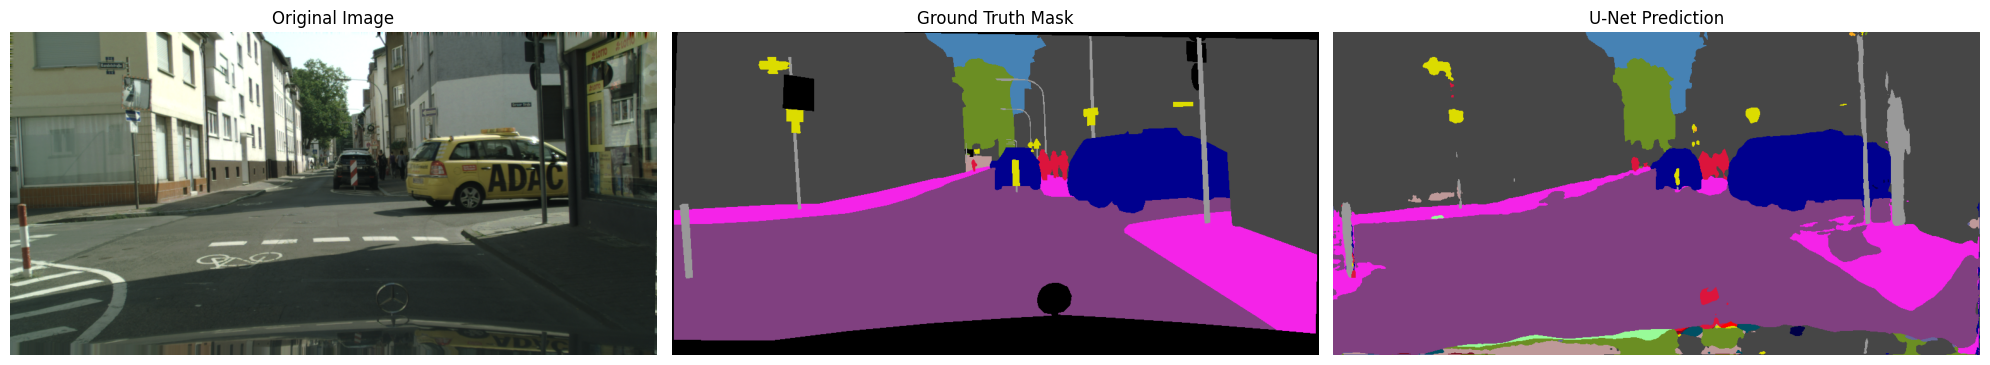

In [ ]:
# Get one batch from validation dataset
images, masks = next(iter(val_dataset))

# Generate predictions
predictions = unet_model.predict(images, verbose=0)

# Convert probabilities into class IDs
predictions = np.argmax(predictions, axis=-1)

# Reverse MobileNetV2 preprocessing for visualization
original_images = np.clip(
    (images.numpy() + 1.0) * 127.5,
    0, 255
).astype(np.uint8)

# Display first validation sample
sample_image = original_images[0]
actual_mask = masks[0].numpy()
predicted_mask = predictions[0]

# Convert masks into RGB colors
def colorize_mask(mask):
    display_mask = np.where(
        mask == IGNORE_LABEL,
        0,
        mask + 1
    )
    return color_table[display_mask]

actual_rgb = colorize_mask(actual_mask)
predicted_rgb = colorize_mask(predicted_mask)

# Plot comparison
fig, axes = plt.subplots(1, 3, figsize=(20, 8))

axes[0].imshow(sample_image)
axes[0].set_title("Original Image")

axes[1].imshow(actual_rgb)
axes[1].set_title("Ground Truth Mask")

axes[2].imshow(predicted_rgb)
axes[2].set_title("U-Net Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# DEEPLABV3+ WITH MOBILENETV2
# ==========================================

def convolution_block(x, filters, kernel_size=3,
                      dilation_rate=1):

    x = layers.Conv2D(
        filters,
        kernel_size,
        padding="same",
        dilation_rate=dilation_rate,
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    return x


# Atrous Spatial Pyramid Pooling
def build_aspp(features):

    input_shape = features.shape
    height = input_shape[1]
    width = input_shape[2]

    # Branch 1: 1x1 convolution
    branch1 = convolution_block(
        features, 256, kernel_size=1
    )

    # Branches 2, 3 and 4: Atrous convolutions
    branch2 = convolution_block(
        features, 256, dilation_rate=6
    )

    branch3 = convolution_block(
        features, 256, dilation_rate=12
    )

    branch4 = convolution_block(
        features, 256, dilation_rate=18
    )

    # Branch 5: Global average pooling
    branch5 = layers.GlobalAveragePooling2D()(
        features
    )

    branch5 = layers.Reshape((1, 1, input_shape[-1]))(
        branch5
    )

    branch5 = convolution_block(
        branch5, 256, kernel_size=1
    )

    branch5 = layers.Resizing(
        height, width, interpolation="bilinear"
    )(branch5)

    # Combine all five branches
    x = layers.Concatenate()([
        branch1,
        branch2,
        branch3,
        branch4,
        branch5
    ])

    x = convolution_block(x, 256, kernel_size=1)

    return x


# Complete DeepLabV3+ model
def build_deeplabv3plus():

    inputs = keras.Input(
        shape=(IMG_HEIGHT, IMG_WIDTH, 3)
    )

    # MobileNetV2 pretrained encoder
    backbone = keras.applications.MobileNetV2(
        input_tensor=inputs,
        include_top=False,
        weights="imagenet"
    )

    backbone.trainable = False

    # Low-level features: 1/4 resolution
    low_level_features = backbone.get_layer(
        "block_3_expand_relu"
    ).output

    # High-level features: 1/16 resolution
    high_level_features = backbone.get_layer(
        "block_13_expand_relu"
    ).output

    # ASPP module
    x = build_aspp(high_level_features)

    # Upsample ASPP output to low-level feature size
    x = layers.UpSampling2D(
        size=(4, 4),
        interpolation="bilinear"
    )(x)

    # Reduce low-level feature channels
    low_level_features = convolution_block(
        low_level_features,
        48,
        kernel_size=1
    )

    # Combine low-level and high-level features
    x = layers.Concatenate()([
        x,
        low_level_features
    ])

    # Decoder
    x = convolution_block(x, 256)
    x = convolution_block(x, 256)

    # Restore original image resolution
    x = layers.UpSampling2D(
        size=(4, 4),
        interpolation="bilinear"
    )(x)

    # Final segmentation output
    outputs = layers.Conv2D(
        NUM_CLASSES,
        kernel_size=1,
        activation="softmax",
        dtype="float32"
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="DeepLabV3Plus_MobileNetV2"
    )

    return model


deeplab_model = build_deeplabv3plus()

print("DeepLabV3+ model created successfully!")
print("Input shape:", deeplab_model.input_shape)
print("Output shape:", deeplab_model.output_shape)

print(
    "Total parameters:",
    f"{deeplab_model.count_params():,}"
)

print(
    "Trainable parameters:",
    f"{sum(np.prod(v.shape) for v in deeplab_model.trainable_weights):,}"
)

/tmp/ipykernel_379/2193333752.py:86: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  backbone = keras.applications.MobileNetV2(


DeepLabV3+ model created successfully!
Input shape: (None, 512, 1024, 3)
Output shape: (None, 512, 1024, 19)
Total parameters: 6,530,579
Trainable parameters: 5,910,131


In [ ]:
print("Total parameters:", deeplab_model.count_params())
print("Trainable parameters:",
      sum(np.prod(v.shape) for v in deeplab_model.trainable_weights))
print("Non-trainable parameters:",
      sum(np.prod(v.shape) for v in deeplab_model.non_trainable_weights))

print("\nMobileNet-related layers:")
for layer in deeplab_model.layers:
    if "mobilenet" in layer.name.lower() or "block_" in layer.name.lower():
        print(layer.name, "Trainable:", layer.trainable)

Total parameters: 6530579
Trainable parameters: 5910131
Non-trainable parameters: 620448

MobileNet-related layers:
block_1_expand Trainable: False
block_1_expand_BN Trainable: False
block_1_expand_relu Trainable: False
block_1_pad Trainable: False
block_1_depthwise Trainable: False
block_1_depthwise_BN Trainable: False
block_1_depthwise_relu Trainable: False
block_1_project Trainable: False
block_1_project_BN Trainable: False
block_2_expand Trainable: False
block_2_expand_BN Trainable: False
block_2_expand_relu Trainable: False
block_2_depthwise Trainable: False
block_2_depthwise_BN Trainable: False
block_2_depthwise_relu Trainable: False
block_2_project Trainable: False
block_2_project_BN Trainable: False
block_2_add Trainable: False
block_3_expand Trainable: False
block_3_expand_BN Trainable: False
block_3_expand_relu Trainable: False
block_3_pad Trainable: False
block_3_depthwise Trainable: False
block_3_depthwise_BN Trainable: False
block_3_depthwise_relu Trainable: False
block_3_

In [ ]:
DEEPLAB_LEARNING_RATE = 0.001

deeplab_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=DEEPLAB_LEARNING_RATE
    ),
    loss=masked_sparse_categorical_crossentropy
)

print("DeepLabV3+ compilation completed!")


DeepLabV3+ compilation completed!


In [ ]:
DEEPLAB_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_deeplabv3plus_model.keras"
)

deeplab_checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=DEEPLAB_MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

deeplab_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

deeplab_reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

deeplab_callbacks = [
    deeplab_checkpoint,
    deeplab_early_stopping,
    deeplab_reduce_lr
]

print("DeepLabV3+ callbacks configured!")
print("Checkpoint:", DEEPLAB_MODEL_PATH)

DeepLabV3+ callbacks configured!
Checkpoint: /content/drive/MyDrive/Road_Segmentation_Models/best_deeplabv3plus_model.keras


In [ ]:
print("Available GPU:", tf.config.list_physical_devices("GPU"))

history_deeplab = deeplab_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=deeplab_callbacks
)

Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Epoch 1/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 0s 378ms/step - loss: 0.4879
Epoch 1: val_loss improved from None to 0.34797, saving model to /content/drive/MyDrive/Road_Segmentation_Models/best_deeplabv3plus_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Road_Segmentation_Models/best_deeplabv3plus_model.keras
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 693s 434ms/step - loss: 0.3870 - val_loss: 0.3480 - learning_rate: 0.0010
Epoch 2/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step - loss: 0.2985
Epoch 2: val_loss improved from 0.34797 to 0.30671, saving model to /content/drive/MyDrive/Road_Segmentation_Models/best_deeplabv3plus_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Road_Segmentation_Models/best_deeplabv3plus_model.keras
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 585s 393ms/step - loss: 0.2917 - val_loss: 0.3067 - learning_rate: 0.0010
Epoch 3/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 0s 36

In [ ]:
# Initialize confusion matrix
deeplab_conf_matrix = tf.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=tf.int64
)

# Evaluate all validation batches
for images, masks in tqdm(
    val_dataset,
    desc="Evaluating DeepLabV3+"
):

    predictions = deeplab_model.predict(
        images,
        verbose=0
    )

    predictions = tf.argmax(
        predictions,
        axis=-1,
        output_type=tf.int32
    )

    actual = tf.reshape(masks, [-1])
    predicted = tf.reshape(predictions, [-1])

    # Exclude ignored pixels
    valid_pixels = tf.not_equal(
        actual,
        IGNORE_LABEL
    )

    actual = tf.boolean_mask(actual, valid_pixels)
    predicted = tf.boolean_mask(predicted, valid_pixels)

    batch_cm = tf.math.confusion_matrix(
        actual,
        predicted,
        num_classes=NUM_CLASSES,
        dtype=tf.int64
    )

    deeplab_conf_matrix += batch_cm

print("DeepLabV3+ evaluation completed!")
print("Confusion matrix:", deeplab_conf_matrix.shape)

Evaluating DeepLabV3+:   0%|          | 0/250 [00:00<?, ?it/s]

DeepLabV3+ evaluation completed!
Confusion matrix: (19, 19)


In [ ]:
deeplab_cm = deeplab_conf_matrix.numpy()

# Pixel Accuracy
deeplab_pixel_accuracy = (
    np.diag(deeplab_cm).sum() / deeplab_cm.sum()
)

# Class-wise IoU
intersection = np.diag(deeplab_cm)

union = (
    deeplab_cm.sum(axis=0)
    + deeplab_cm.sum(axis=1)
    - intersection
)

deeplab_class_iou = np.divide(
    intersection,
    union,
    out=np.zeros(NUM_CLASSES, dtype=float),
    where=union != 0
)

present_classes = union > 0

deeplab_miou = deeplab_class_iou[present_classes].mean()

print(f"Pixel Accuracy: {deeplab_pixel_accuracy * 100:.2f}%")
print(f"Mean IoU: {deeplab_miou * 100:.2f}%")

Pixel Accuracy: 92.26%
Mean IoU: 55.04%


In [ ]:
class_names = [
    "Road", "Sidewalk", "Building", "Wall", "Fence",
    "Pole", "Traffic Light", "Traffic Sign", "Vegetation",
    "Terrain", "Sky", "Person", "Rider", "Car",
    "Truck", "Bus", "Train", "Motorcycle", "Bicycle"
]

deeplab_results = pd.DataFrame({
    "Class": class_names,
    "IoU (%)": deeplab_class_iou * 100,
    "Union Pixels": union
})

deeplab_results = deeplab_results.sort_values(
    by="IoU (%)", ascending=False
).reset_index(drop=True)

display(deeplab_results.round(2))

,Class,IoU (%),Union Pixels
0,Road,95.72,88382593
1,Sky,91.58,8098975
2,Vegetation,88.32,42125482
3,Car,87.81,16264515
4,Building,86.41,54723545
5,Sidewalk,69.80,14455867
6,Person,63.07,3706576
7,Bicycle,61.04,1949516
8,Traffic Sign,54.89,1719847
9,Terrain,50.59,2617568


In [ ]:
import time

# Use one validation image
sample_images, sample_masks = next(iter(val_dataset))
sample_image = sample_images[:1]

def benchmark_model(model, model_name, warmup=5, runs=30):

    # Warm-up
    for _ in range(warmup):
        _ = model(sample_image, training=False)

    # Ensure GPU operations are complete
    _ = tf.reduce_sum(
        model(sample_image, training=False)
    ).numpy()

    start_time = time.perf_counter()

    for _ in range(runs):
        predictions = model(sample_image, training=False)

    # Synchronize GPU
    _ = tf.reduce_sum(predictions).numpy()

    total_time = time.perf_counter() - start_time

    avg_time = total_time / runs
    fps = 1 / avg_time

    print(f"\n{model_name}")
    print(f"Average inference time: {avg_time * 1000:.2f} ms")
    print(f"FPS: {fps:.2f}")

    return avg_time, fps


unet_time, unet_fps = benchmark_model(
    unet_model, "U-Net"
)

deeplab_time, deeplab_fps = benchmark_model(
    deeplab_model, "DeepLabV3+"
)


U-Net
Average inference time: 178.91 ms
FPS: 5.59

DeepLabV3+
Average inference time: 166.19 ms
FPS: 6.02


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

MODEL_DIR = "/content/drive/MyDrive/Road_Segmentation_Models"

print("Available model files:")
print(os.listdir(MODEL_DIR))

Available model files:
['best_unet_model.keras', 'best_deeplabv3plus_model.keras']


In [ ]:
import tensorflow as tf
from tensorflow import keras

IGNORE_LABEL = 255

def masked_sparse_categorical_crossentropy(y_true, y_pred):

    y_true = tf.cast(y_true, tf.int32)

    valid_mask = tf.not_equal(y_true, IGNORE_LABEL)

    safe_labels = tf.where(
        valid_mask,
        y_true,
        tf.zeros_like(y_true)
    )

    loss = keras.losses.sparse_categorical_crossentropy(
        safe_labels, y_pred
    )

    valid_mask = tf.cast(valid_mask, tf.float32)
    loss = loss * valid_mask

    return tf.reduce_sum(loss) / (
        tf.reduce_sum(valid_mask) + 1e-7
    )


MODEL_PATH = "/content/drive/MyDrive/Road_Segmentation_Models/best_unet_model.keras"

unet_model = keras.models.load_model(
    MODEL_PATH,
    custom_objects={
        "masked_sparse_categorical_crossentropy":
            masked_sparse_categorical_crossentropy
    }
)

print("U-Net model loaded successfully!")
print("Input shape:", unet_model.input_shape)
print("Output shape:", unet_model.output_shape)

U-Net model loaded successfully!
Input shape: (None, 512, 1024, 3)
Output shape: (None, 512, 1024, 19)


In [ ]:
from google.colab import files

uploaded = files.upload()

video_path = next(iter(uploaded.keys()))

print("Video uploaded successfully!")
print("Video path:", video_path)

Saving Dash_cam.mp4 to Dash_cam (1).mp4
Video uploaded successfully!
Video path: Dash_cam (1).mp4


In [ ]:
import cv2

video = cv2.VideoCapture(video_path)

if not video.isOpened():
    raise ValueError("Unable to open the uploaded video!")

# Extract video properties
video_fps = video.get(cv2.CAP_PROP_FPS)
total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))

video_width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
video_height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = total_frames / video_fps

print("Video Information")
print("-------------------------")
print(f"Resolution: {video_width} x {video_height}")
print(f"FPS: {video_fps:.2f}")
print(f"Total Frames: {total_frames}")
print(f"Duration: {duration:.2f} seconds")

video.release()

Video Information
-------------------------
Resolution: 3840 x 2160
FPS: 29.97
Total Frames: 1537
Duration: 51.28 seconds


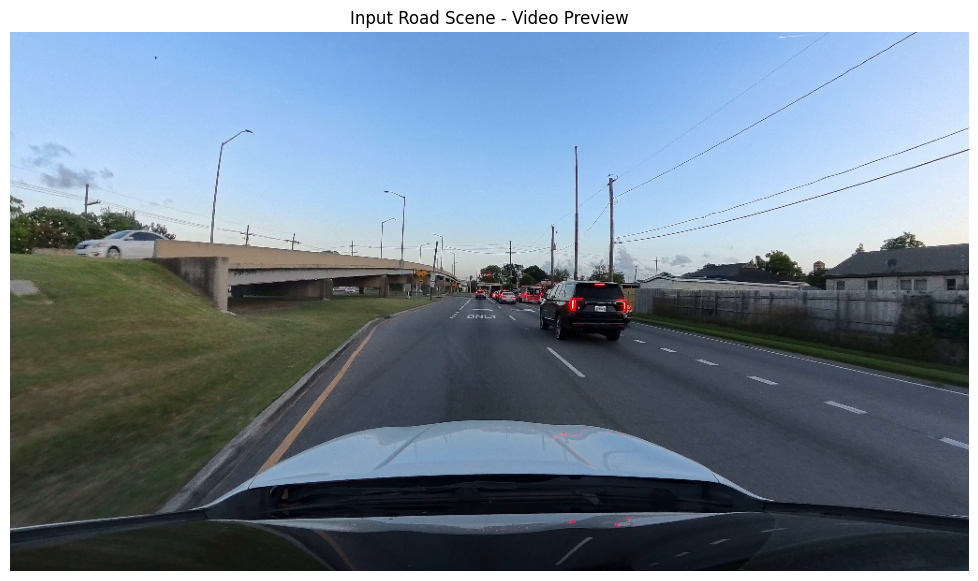

In [ ]:
import matplotlib.pyplot as plt
import cv2

video = cv2.VideoCapture(video_path)

success, frame = video.read()
video.release()

if not success:
    raise ValueError("Could not read the video frame!")

# Convert BGR to RGB for display
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

# Resize only for preview
preview = cv2.resize(frame_rgb, (1024, 576))

plt.figure(figsize=(14, 7))
plt.imshow(preview)
plt.title("Input Road Scene - Video Preview")
plt.axis("off")
plt.show()

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import cv2

# Read one frame
video = cv2.VideoCapture(video_path)
success, frame = video.read()
video.release()

if not success:
    raise ValueError("Could not read video frame!")

# Preserve 2:1 aspect ratio using center crop
h, w = frame.shape[:2]

crop_height = w // 2
y_start = (h - crop_height) // 2
y_end = y_start + crop_height

cropped_frame = frame[y_start:y_end, :, :]

# Convert BGR to RGB
frame_rgb = cv2.cvtColor(cropped_frame, cv2.COLOR_BGR2RGB)

# Resize to model input dimensions
resized_frame = cv2.resize(
    frame_rgb,
    (1024, 512),
    interpolation=cv2.INTER_LINEAR
)

# Apply MobileNetV2 preprocessing
input_image = keras.applications.mobilenet_v2.preprocess_input(
    resized_frame.astype(np.float32)
)

# Add batch dimension
input_image = np.expand_dims(input_image, axis=0)

# Predict segmentation
prediction = unet_model.predict(input_image, verbose=0)

# Convert probabilities to class IDs
predicted_mask = np.argmax(prediction[0], axis=-1).astype(np.uint8)

print("Prediction completed!")
print("Mask shape:", predicted_mask.shape)
print("Detected class IDs:", np.unique(predicted_mask))

Prediction completed!
Mask shape: (512, 1024)
Detected class IDs: [ 0  1  2  3  4  5  6  8  9 10 11 12 13 16 17 18]


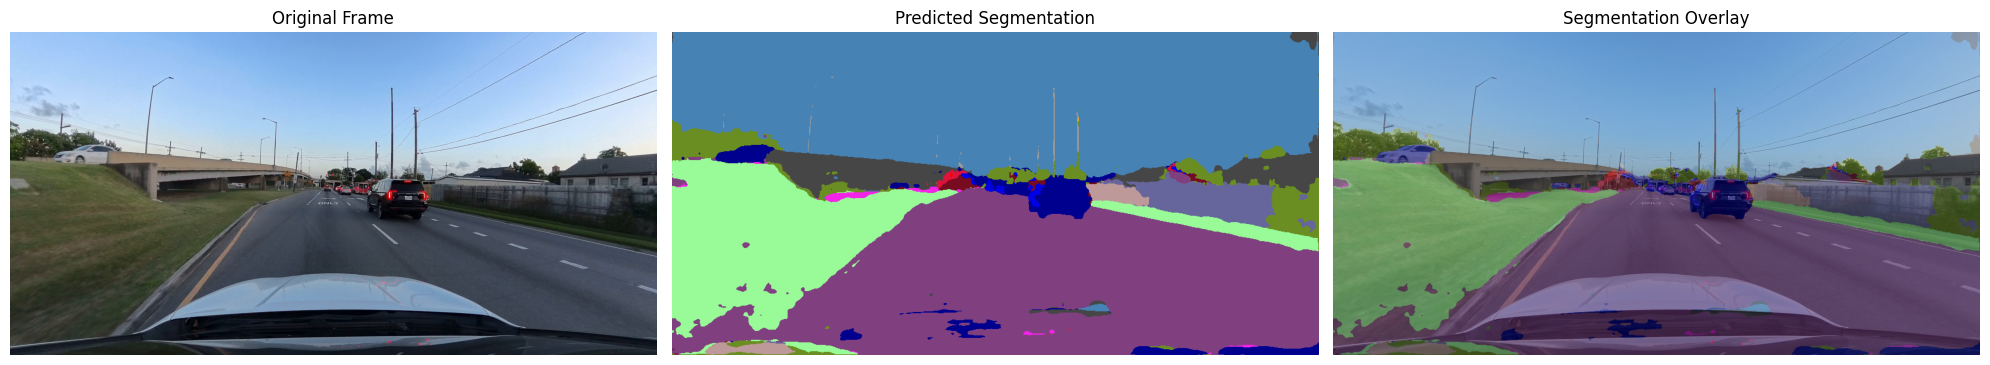

In [ ]:
# Cityscapes 19-class color palette (RGB)
color_palette = np.array([
    [128, 64, 128],   # Road
    [244, 35, 232],   # Sidewalk
    [70, 70, 70],     # Building
    [102, 102, 156],  # Wall
    [190, 153, 153],  # Fence
    [153, 153, 153],  # Pole
    [250, 170, 30],   # Traffic Light
    [220, 220, 0],    # Traffic Sign
    [107, 142, 35],   # Vegetation
    [152, 251, 152],  # Terrain
    [70, 130, 180],   # Sky
    [220, 20, 60],    # Person
    [255, 0, 0],      # Rider
    [0, 0, 142],      # Car
    [0, 0, 70],       # Truck
    [0, 60, 100],     # Bus
    [0, 80, 100],     # Train
    [0, 0, 230],      # Motorcycle
    [119, 11, 32]     # Bicycle
], dtype=np.uint8)

# Convert class IDs into RGB colors
colored_mask = color_palette[predicted_mask]

# Resize mask to original cropped frame dimensions
mask_resized = cv2.resize(
    colored_mask,
    (cropped_frame.shape[1], cropped_frame.shape[0]),
    interpolation=cv2.INTER_NEAREST
)

# Blend original frame and segmentation mask
overlay = cv2.addWeighted(
    frame_rgb, 0.55,
    mask_resized, 0.45,
    0
)

# Display results
plt.figure(figsize=(20, 7))

plt.subplot(1, 3, 1)
plt.imshow(frame_rgb)
plt.title("Original Frame")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(colored_mask)
plt.title("Predicted Segmentation")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Segmentation Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:

import time
from tqdm import tqdm

# Output video path
output_path = "/content/segmented_road_video.mp4"

# Reopen input video
cap = cv2.VideoCapture(video_path)

# Preserve original video properties
original_fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
original_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
original_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Configure video writer
fourcc = cv2.VideoWriter_fourcc(*'mp4v')

out = cv2.VideoWriter(
    output_path,
    fourcc,
    original_fps,
    (original_width, original_height)
)

if not out.isOpened():
    raise RuntimeError("Could not initialize output video writer!")

start_time = time.perf_counter()
processed_frames = 0

for _ in tqdm(range(total_frames), desc="Segmenting video"):

    success, frame = cap.read()

    if not success:
        break

    # Center crop to preserve model's 2:1 aspect ratio
    h, w = frame.shape[:2]
    crop_height = w // 2

    y_start = (h - crop_height) // 2
    y_end = y_start + crop_height

    cropped_frame = frame[y_start:y_end, :]

    # Convert BGR to RGB
    frame_rgb = cv2.cvtColor(
        cropped_frame, cv2.COLOR_BGR2RGB
    )

    # Resize to U-Net input dimensions
    resized_frame = cv2.resize(
        frame_rgb,
        (1024, 512),
        interpolation=cv2.INTER_LINEAR
    )

    # Normalize using MobileNetV2 preprocessing
    input_image = keras.applications.mobilenet_v2.preprocess_input(
        resized_frame.astype(np.float32)
    )

    input_image = np.expand_dims(input_image, axis=0)

    # Predict segmentation
    prediction = unet_model(input_image, training=False)

    predicted_mask = tf.argmax(
        prediction[0],
        axis=-1
    ).numpy().astype(np.uint8)

    # Generate colored segmentation mask
    colored_mask = color_palette[predicted_mask]

    # Resize mask to original cropped dimensions
    mask_resized = cv2.resize(
        colored_mask,
        (w, crop_height),
        interpolation=cv2.INTER_NEAREST
    )

    # Blend original frame with segmentation
    overlay = cv2.addWeighted(
        frame_rgb, 0.55,
        mask_resized, 0.45,
        0
    )

    # Convert RGB to BGR for OpenCV writer
    overlay_bgr = cv2.cvtColor(
        overlay, cv2.COLOR_RGB2BGR
    )

    # Restore original height using black top/bottom padding
    final_frame = np.zeros(
        (original_height, original_width, 3),
        dtype=np.uint8
    )

    final_frame[y_start:y_end, :] = overlay_bgr

    out.write(final_frame)

    processed_frames += 1

# Release resources
cap.release()
out.release()

total_time = time.perf_counter() - start_time

print("\nVideo segmentation completed!")
print(f"Processed frames: {processed_frames}")
print(f"Processing time: {total_time:.2f} seconds")
print(f"Average processing FPS: {processed_frames / total_time:.2f}")
print(f"Output video: {output_path}")


Segmenting video: 100%|██████████| 1537/1537 [10:01<00:00,  2.56it/s]


Video segmentation completed!
Processed frames: 1537
Processing time: 601.49 seconds
Average processing FPS: 2.56
Output video: /content/segmented_road_video.mp4


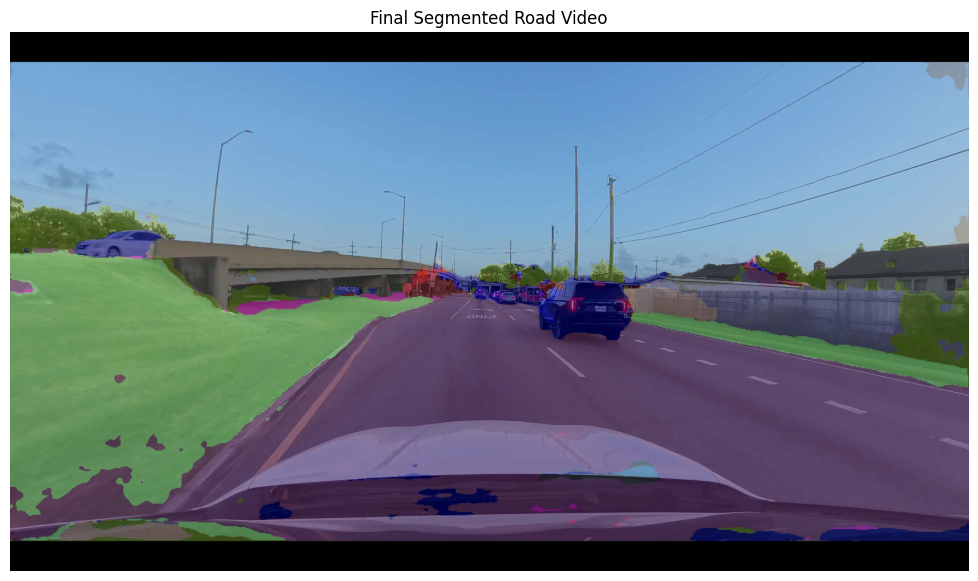

In [ ]:
# Open segmented output video
output_video = cv2.VideoCapture(output_path)

if not output_video.isOpened():
    raise ValueError("Could not open segmented video!")

# Read a frame
success, output_frame = output_video.read()

output_video.release()

if success:
    output_rgb = cv2.cvtColor(
        output_frame, cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(14, 7))
    plt.imshow(output_rgb)
    plt.title("Final Segmented Road Video")
    plt.axis("off")
    plt.show()
else:
    print("Could not read output frame!")

In [ ]:
import numpy as np
import pandas as pd

NUM_CLASSES = 19

class_names = [
    "Road", "Sidewalk", "Building", "Wall", "Fence",
    "Pole", "Traffic Light", "Traffic Sign", "Vegetation",
    "Terrain", "Sky", "Person", "Rider", "Car",
    "Truck", "Bus", "Train", "Motorcycle", "Bicycle"
]

# Count pixels belonging to each class
pixel_counts = np.bincount(
    predicted_mask.flatten(),
    minlength=NUM_CLASSES
)

# Calculate percentage of image area
total_pixels = pixel_counts.sum()

class_percentages = (
    pixel_counts / total_pixels
) * 100

# Create analytics table
scene_analytics = pd.DataFrame({
    "Class": class_names,
    "Pixel Count": pixel_counts,
    "Area Percentage": class_percentages
})

scene_analytics = scene_analytics.sort_values(
    by="Area Percentage",
    ascending=False
).reset_index(drop=True)

display(scene_analytics.round(2))

,Class,Pixel Count,Area Percentage
0,Sky,176821,33.73
1,Road,158136,30.16
2,Car,109198,20.83
3,Building,51681,9.86
4,Vegetation,15839,3.02
5,Terrain,2504,0.48
6,Sidewalk,1941,0.37
7,Fence,1771,0.34
8,Traffic Sign,1752,0.33
9,Bicycle,1493,0.28


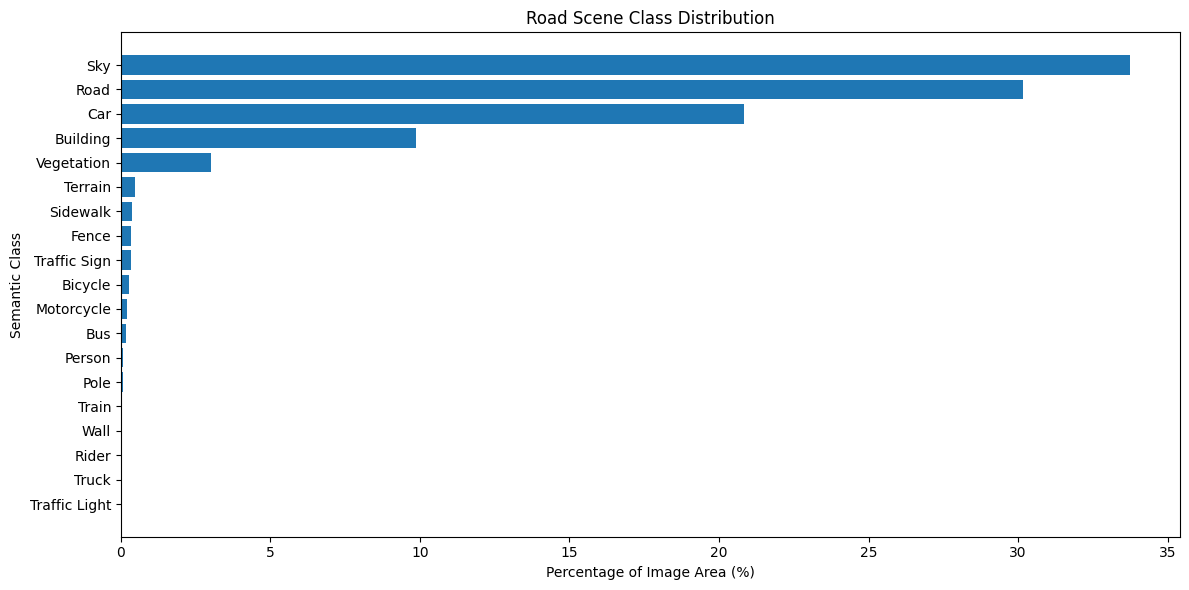

In [ ]:
plt.figure(figsize=(12, 6))

plt.barh(
    scene_analytics["Class"],
    scene_analytics["Area Percentage"]
)

plt.xlabel("Percentage of Image Area (%)")
plt.ylabel("Semantic Class")
plt.title("Road Scene Class Distribution")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
%pip install -q ultralytics

In [ ]:
import ultralytics

print("Ultralytics version:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.208


In [ ]:
from ultralytics import YOLO

# Load pretrained YOLOv8 Nano model
yolo_model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")

YOLO model loaded successfully!


In [ ]:
print("TensorFlow GPU:", tf.config.list_physical_devices('GPU'))
print("YOLO device:", yolo_model.device)

TensorFlow GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
YOLO device: cpu


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("CUDA is not available to PyTorch!")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU name: Tesla T4


In [ ]:
results = yolo_model.predict(
    source=frame_rgb,
    device=0,
    conf=0.25,
    verbose=False
)

print("YOLO inference completed!")

YOLO inference completed!


In [ ]:
print("Prediction device:", results[0].speed)

Prediction device: {'preprocess': 247.46397000035358, 'inference': 8.530218000487366, 'postprocess': 51.931739999417914}


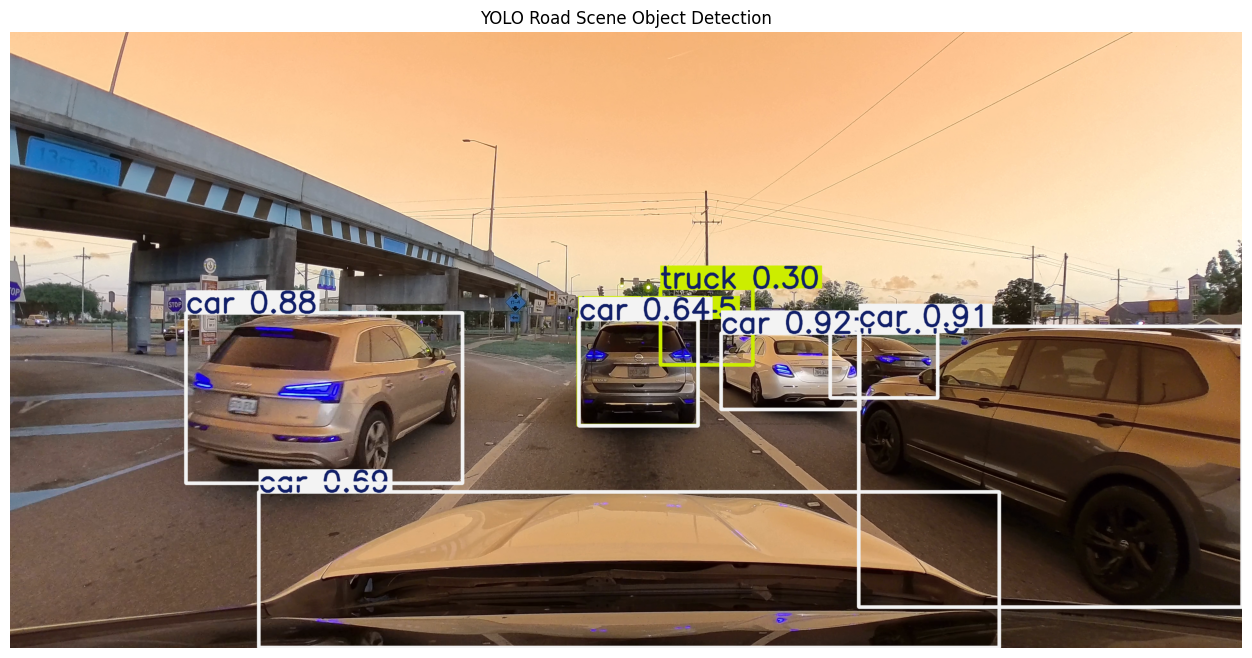

In [ ]:
# Get annotated detection image
annotated_frame = results[0].plot()

# Convert BGR to RGB for Matplotlib
annotated_frame_rgb = cv2.cvtColor(
    annotated_frame,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(16, 8))
plt.imshow(annotated_frame_rgb)
plt.title("YOLO Road Scene Object Detection")
plt.axis("off")
plt.show()

In [ ]:
# Extract detection information
boxes = results[0].boxes

detected_objects = []

for box in boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    class_name = yolo_model.names[class_id]

    detected_objects.append({
        "Object": class_name,
        "Confidence": round(confidence, 3)
    })

detection_df = pd.DataFrame(detected_objects)

if not detection_df.empty:
    display(detection_df)
else:
    print("No objects detected.")

,Object,Confidence
0,car,0.915
1,car,0.909
2,car,0.884
3,car,0.695
4,car,0.639
5,truck,0.454
6,car,0.399
7,truck,0.305


,Object,Count
0,car,6
1,truck,2


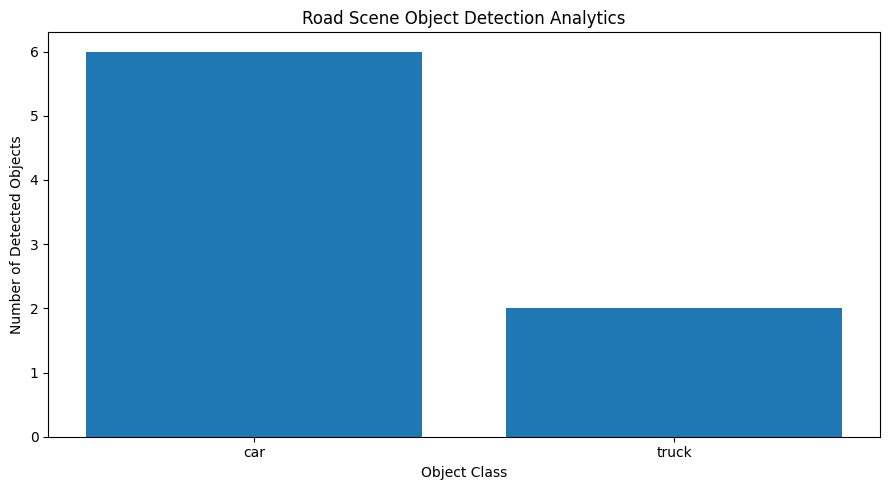

In [ ]:
# Count detected objects by class
object_counts = detection_df["Object"].value_counts()

# Create analytics dataframe
object_analytics = pd.DataFrame({
    "Object": object_counts.index,
    "Count": object_counts.values
})

display(object_analytics)

# Plot object counts
plt.figure(figsize=(9, 5))

plt.bar(
    object_analytics["Object"],
    object_analytics["Count"]
)

plt.xlabel("Object Class")
plt.ylabel("Number of Detected Objects")
plt.title("Road Scene Object Detection Analytics")

plt.tight_layout()
plt.show()

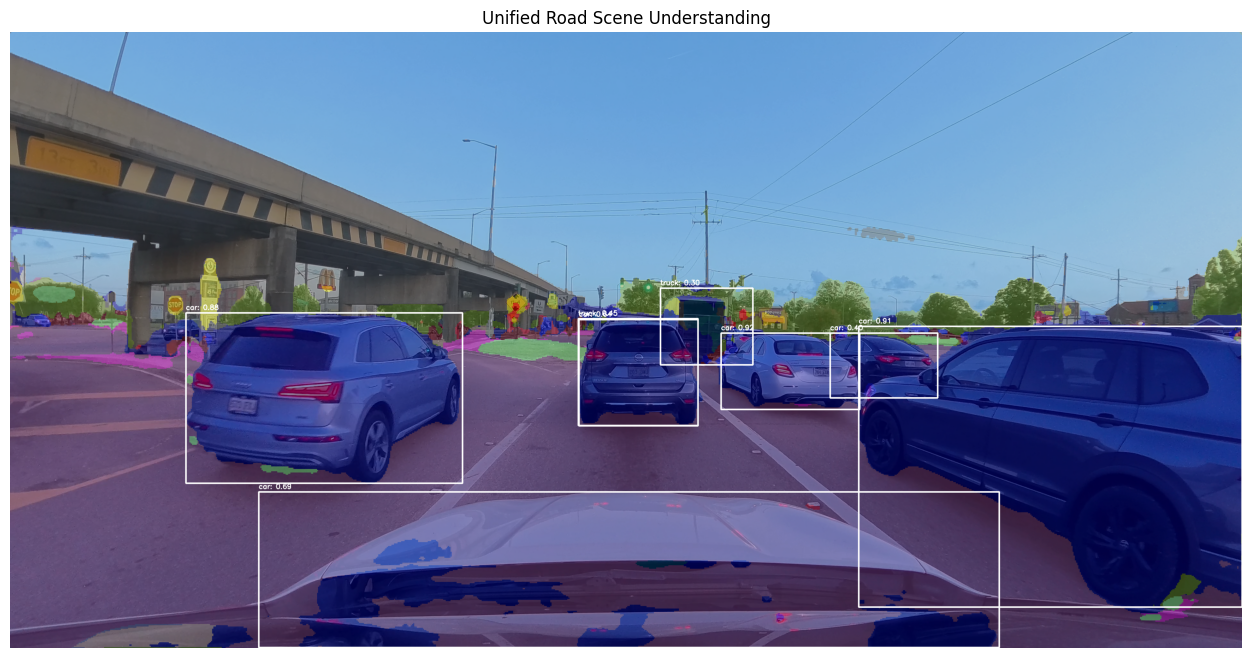

In [ ]:
# Resize mask to match the high-resolution frame size
mask_resized = cv2.resize(
    colored_mask,
    (frame_rgb.shape[1], frame_rgb.shape[0]),
    interpolation=cv2.INTER_NEAREST
)

# Create segmentation overlay using the matched sizes
combined_image = cv2.addWeighted(
    frame_rgb, 0.55,
    mask_resized, 0.45,
    0
)

# Get YOLO bounding box coordinates
boxes = results[0].boxes

# Draw YOLO detections over segmentation
for box in boxes:
    x1, y1, x2, y2 = map(
        int, box.xyxy[0].cpu().numpy()
    )

    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    class_name = yolo_model.names[class_id]

    # Draw bounding box
    cv2.rectangle(
        combined_image,
        (x1, y1),
        (x2, y2),
        (255, 255, 255),
        3
    )

    # Add label
    label = f"{class_name}: {confidence:.2f}"

    cv2.putText(
        combined_image,
        label,
        (x1, max(y1 - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2
    )

# Display combined output
plt.figure(figsize=(16, 8))
plt.imshow(combined_image)
plt.title("Unified Road Scene Understanding")
plt.axis("off")
plt.show()

In [ ]:
results_filtered = yolo_model.predict(
    source=frame_rgb,
    device=0,
    conf=0.50,
    iou=0.45,
    verbose=False
)

print("Filtered detection count:", len(results_filtered[0].boxes))

Filtered detection count: 5


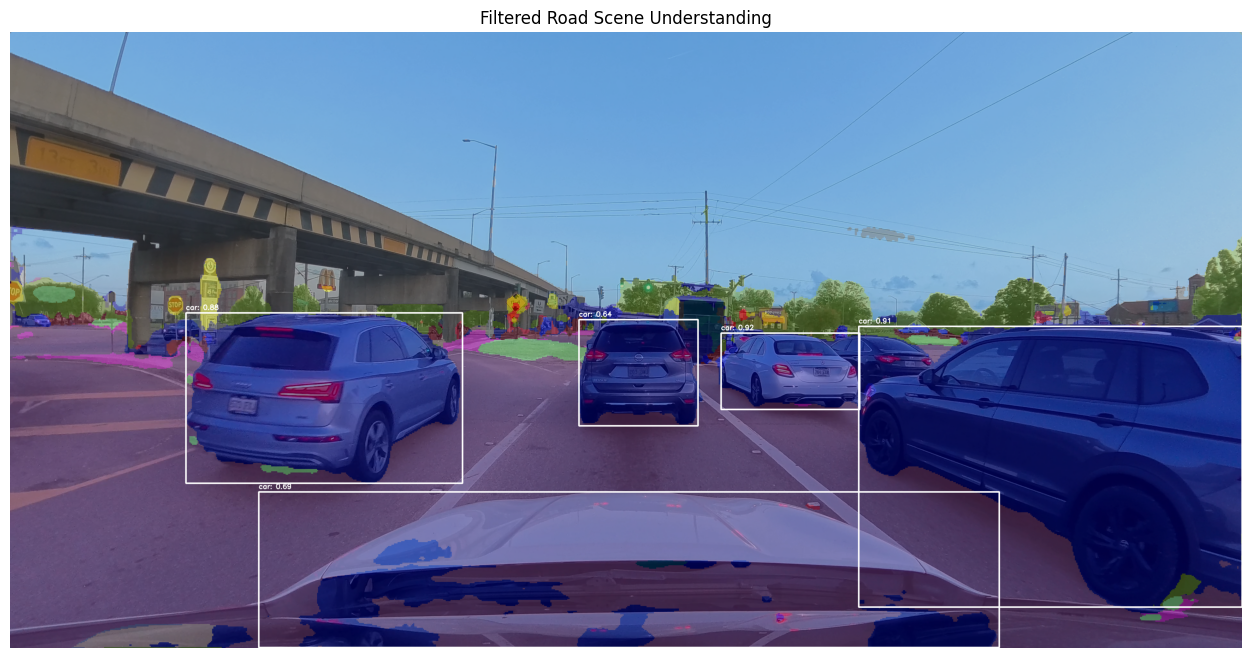

In [ ]:
# Resize colored mask to match the high-resolution cropped frame
mask_resized = cv2.resize(
    colored_mask,
    (frame_rgb.shape[1], frame_rgb.shape[0]),
    interpolation=cv2.INTER_NEAREST
)

# Blend original frame and resized segmentation mask
filtered_image = cv2.addWeighted(
    frame_rgb, 0.55,
    mask_resized, 0.45,
    0
)

for box in results_filtered[0].boxes:
    x1, y1, x2, y2 = map(
        int, box.xyxy[0].cpu().numpy()
    )

    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    class_name = yolo_model.names[class_id]

    cv2.rectangle(
        filtered_image,
        (x1, y1),
        (x2, y2),
        (255, 255, 255),
        3
    )

    cv2.putText(
        filtered_image,
        f"{class_name}: {confidence:.2f}",
        (x1, max(y1 - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2
    )

plt.figure(figsize=(16, 8))
plt.imshow(filtered_image)
plt.title("Filtered Road Scene Understanding")
plt.axis("off")
plt.show()

In [ ]:
import time
from tqdm import tqdm

combined_output_path = "/content/combined_road_scene_video.mp4"

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

fourcc = cv2.VideoWriter_fourcc(*'mp4v')

out = cv2.VideoWriter(
    combined_output_path,
    fourcc,
    fps,
    (width, height)
)

if not out.isOpened():
    raise RuntimeError("Could not initialize output video!")

processed_frames = 0
total_detections = 0
object_counts_video = {}

start_time = time.perf_counter()

for _ in tqdm(range(total_frames), desc="Combined video processing"):

    success, frame = cap.read()

    if not success:
        break

    # Center crop to maintain 2:1 aspect ratio
    h, w = frame.shape[:2]
    crop_height = w // 2

    y_start = (h - crop_height) // 2
    y_end = y_start + crop_height

    cropped_frame = frame[y_start:y_end, :]

    frame_rgb = cv2.cvtColor(
        cropped_frame, cv2.COLOR_BGR2RGB
    )

    resized_frame = cv2.resize(
        frame_rgb,
        (1024, 512),
        interpolation=cv2.INTER_LINEAR
    )

    # -------------------------------
    # 1. U-Net Semantic Segmentation
    # -------------------------------

    input_image = keras.applications.mobilenet_v2.preprocess_input(
        resized_frame.astype(np.float32)
    )

    input_image = np.expand_dims(input_image, axis=0)

    prediction = unet_model(
        input_image, training=False
    )

    predicted_mask = tf.argmax(
        prediction[0], axis=-1
    ).numpy().astype(np.uint8)

    colored_mask = color_palette[predicted_mask]

    # FIX: Resize colored_mask to match high-resolution frame_rgb
    mask_resized = cv2.resize(
        colored_mask,
        (frame_rgb.shape[1], frame_rgb.shape[0]),
        interpolation=cv2.INTER_NEAREST
    )

    # Blend segmentation with original frame
    combined_image = cv2.addWeighted(
        frame_rgb, 0.55,
        mask_resized, 0.45,
        0
    )

    # -------------------------------
    # 2. YOLO Object Detection
    # -------------------------------

    # Inference is done on high-res frame to detect fine details accurately
    yolo_results = yolo_model.predict(
        source=frame_rgb,
        device=0,
        conf=0.50,
        iou=0.45,
        verbose=False
    )

    boxes = yolo_results[0].boxes

    for box in boxes:

        x1, y1, x2, y2 = map(
            int, box.xyxy[0].cpu().numpy()
        )

        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        class_name = yolo_model.names[class_id]

        # Count detected objects
        object_counts_video[class_name] = (
            object_counts_video.get(class_name, 0) + 1
        )

        total_detections += 1

        # Draw bounding box
        cv2.rectangle(
            combined_image,
            (x1, y1),
            (x2, y2),
            (255, 255, 255),
            2
        )

        label = f"{class_name}: {confidence:.2f}"

        cv2.putText(
            combined_image,
            label,
            (x1, max(y1 - 8, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 255, 255),
            2
        )

    # -------------------------------
    # 3. Restore original dimensions
    # -------------------------------

    combined_bgr = cv2.cvtColor(
        combined_image, cv2.COLOR_RGB2BGR
    )

    final_frame = np.zeros(
        (height, width, 3),
        dtype=np.uint8
    )

    final_frame[y_start:y_end, :] = cv2.resize(
        combined_bgr,
        (width, crop_height),
        interpolation=cv2.INTER_LINEAR
    )

    out.write(final_frame)

    processed_frames += 1

cap.release()
out.release()

processing_time = time.perf_counter() - start_time

print("\nCombined processing completed!")
print("Processed frames:", processed_frames)
print(f"Processing time: {processing_time:.2f} seconds")
print(f"Processing FPS: {processed_frames / processing_time:.2f}")
print("Total detections across frames:", total_detections)

print("\nObject detection summary:")
display(pd.DataFrame(
    list(object_counts_video.items()),
    columns=["Object", "Total Frame Detections"]
).sort_values("Total Frame Detections", ascending=False))

print("\nOutput:", combined_output_path)

Combined video processing: 100%|██████████| 1537/1537 [10:24<00:00,  2.46it/s]


Combined processing completed!
Processed frames: 1537
Processing time: 625.00 seconds
Processing FPS: 2.46
Total detections across frames: 5785

Object detection summary:


,Object,Total Frame Detections
0,car,5700
1,truck,84
2,person,1



Output: /content/combined_road_scene_video.mp4


In [ ]:
drive_combined_path = (
    "/content/drive/MyDrive/Road_Segmentation_Models/"
    "combined_road_scene_video.mp4"
)

!cp "/content/combined_road_scene_video.mp4" "{drive_combined_path}"

print("Combined video saved successfully!")
print(drive_combined_path)

Combined video saved successfully!
/content/drive/MyDrive/Road_Segmentation_Models/combined_road_scene_video.mp4


In [ ]:
preview_video = cv2.VideoCapture(combined_output_path)

success, combined_preview = preview_video.read()

preview_video.release()

if success:
    combined_preview_rgb = cv2.cvtColor(
        combined_preview,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(16, 8))
    plt.imshow(combined_preview_rgb)
    plt.title("Combined U-Net + YOLO Video Output")
    plt.axis("off")
    plt.show()
else:
    print("Unable to read combined output video!")

Unable to read combined output video!


In [ ]:
import os

print("Original output exists:",
      os.path.exists(combined_output_path))

print("Output file size:",
      round(os.path.getsize(combined_output_path) / (1024 * 1024), 2),
      "MB")

print("Drive copy exists:",
      os.path.exists(drive_combined_path))

print("Drive file size:",
      round(os.path.getsize(drive_combined_path) / (1024 * 1024), 2),
      "MB")

Original output exists: True
Output file size: 289.2 MB
Drive copy exists: True
Drive file size: 289.2 MB


In [ ]:
test_video = cv2.VideoCapture(combined_output_path)

print("Video opened:", test_video.isOpened())
print("FPS:", test_video.get(cv2.CAP_PROP_FPS))
print("Frame count:", test_video.get(cv2.CAP_PROP_FRAME_COUNT))
print("Width:", test_video.get(cv2.CAP_PROP_FRAME_WIDTH))
print("Height:", test_video.get(cv2.CAP_PROP_FRAME_HEIGHT))

success, test_frame = test_video.read()

print("First frame readable:", success)

test_video.release()

Video opened: False
FPS: 0.0
Frame count: 0.0
Width: 0.0
Height: 0.0
First frame readable: False


In [ ]:
!ffprobe -v error -show_entries stream=codec_name,width,height,r_frame_rate -show_entries format=duration,size -of default=noprint_wrappers=1 "/content/combined_road_scene_video.mp4"

duration=N/A
size=303245532


In [ ]:
!ffmpeg -v error -i "/content/combined_road_scene_video.mp4" -f null -

[out#0/null @ 0x5bce682763c0] Output file does not contain any stream
Error opening output file -.
Error opening output files: Invalid argument


In [ ]:
test_unet = cv2.VideoCapture(
    "/content/segmented_road_video.mp4"
)

print("U-Net video opened:", test_unet.isOpened())
print("U-Net frame count:",
      test_unet.get(cv2.CAP_PROP_FRAME_COUNT))

test_unet.release()

U-Net video opened: True
U-Net frame count: 1537.0


In [ ]:
import subprocess

files_to_check = [
    "/content/segmented_road_video.mp4",
    "/content/combined_road_scene_video.mp4"
]

for path in files_to_check:
    print("\nChecking:", path)

    result = subprocess.run(
        ["ffprobe", "-v", "error", "-show_streams", path],
        capture_output=True,
        text=True
    )

    print(result.stdout[:2000] if result.stdout else result.stderr)


Checking: /content/segmented_road_video.mp4
[STREAM]
index=0
codec_name=mpeg4
codec_long_name=MPEG-4 part 2
profile=Simple Profile
codec_type=video
codec_tag_string=mp4v
codec_tag=0x7634706d
width=3840
height=2160
coded_width=3840
coded_height=2160
closed_captions=0
film_grain=0
has_b_frames=0
sample_aspect_ratio=1:1
display_aspect_ratio=16:9
pix_fmt=yuv420p
level=1
color_range=unknown
color_space=unknown
color_transfer=unknown
color_primaries=unknown
chroma_location=left
field_order=unknown
refs=1
quarter_sample=false
divx_packed=false
id=0x1
r_frame_rate=2997/100
avg_frame_rate=2997/100
time_base=1/11988
start_pts=0
start_time=0.000000
duration_ts=614800
duration=51.284618
bit_rate=43342106
max_bit_rate=N/A
bits_per_raw_sample=N/A
nb_frames=1537
nb_read_frames=N/A
nb_read_packets=N/A
extradata_size=47
DISPOSITION:default=1
DISPOSITION:dub=0
DISPOSITION:original=0
DISPOSITION:comment=0
DISPOSITION:lyrics=0
DISPOSITION:karaoke=0
DISPOSITION:forced=0
DISPOSITION:hearing_impaired=0
DISP

In [ ]:
!ffmpeg -encoders | grep -E "libx264|mpeg4"

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [ ]:

import cv2
import os
import subprocess

input_path = "/content/segmented_road_video.mp4"
test_path = "/content/test_writer.mp4"

cap = cv2.VideoCapture(input_path)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(test_path, fourcc, fps, (width, height))

print("Input opened:", cap.isOpened())
print("Writer opened:", writer.isOpened())
print("Resolution:", width, "x", height)
print("FPS:", fps)

frames_written = 0

while frames_written < 30:
    ret, frame = cap.read()

    if not ret:
        break

    writer.write(frame)
    frames_written += 1

writer.release()
cap.release()

print("Frames written:", frames_written)
print("Test file exists:", os.path.exists(test_path))
print("Test file size:", os.path.getsize(test_path) if os.path.exists(test_path) else 0)

# Verify the generated video
test_cap = cv2.VideoCapture(test_path)

print("Test video readable:", test_cap.isOpened())
print("Test frame count:", test_cap.get(cv2.CAP_PROP_FRAME_COUNT))

ret, test_frame = test_cap.read()
print("First frame readable:", ret)

test_cap.release()

# Check the video stream using FFprobe
result = subprocess.run(
    ["ffprobe", "-v", "error", "-show_streams", test_path],
    capture_output=True,
    text=True
)

print("\nFFprobe output:")
print(result.stdout if result.stdout else result.stderr)


Input opened: True
Writer opened: True
Resolution: 3840 x 2160
FPS: 29.97
Frames written: 30
Test file exists: True
Test file size: 6367426
Test video readable: True
Test frame count: 30.0
First frame readable: True

FFprobe output:
[STREAM]
index=0
codec_name=mpeg4
codec_long_name=MPEG-4 part 2
profile=Simple Profile
codec_type=video
codec_tag_string=mp4v
codec_tag=0x7634706d
width=3840
height=2160
coded_width=3840
coded_height=2160
closed_captions=0
film_grain=0
has_b_frames=0
sample_aspect_ratio=1:1
display_aspect_ratio=16:9
pix_fmt=yuv420p
level=1
color_range=unknown
color_space=unknown
color_transfer=unknown
color_primaries=unknown
chroma_location=left
field_order=unknown
refs=1
quarter_sample=false
divx_packed=false
id=0x1
r_frame_rate=2997/100
avg_frame_rate=2997/100
time_base=1/11988
start_pts=0
start_time=0.000000
duration_ts=12000
duration=1.001001
bit_rate=50879829
max_bit_rate=N/A
bits_per_raw_sample=N/A
nb_frames=30
nb_read_frames=N/A
nb_read_packets=N/A
extradata_size=47


In [ ]:

original_video_path = "Dash_cam (1).mp4"
segmented_video_path = "/content/segmented_road_video.mp4"

original_cap = cv2.VideoCapture(original_video_path)
segmented_cap = cv2.VideoCapture(segmented_video_path)

def get_video_info(cap):
    return {
        "opened": cap.isOpened(),
        "frames": int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
        "width": int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
        "height": int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
        "fps": cap.get(cv2.CAP_PROP_FPS)
    }

original_info = get_video_info(original_cap)
segmented_info = get_video_info(segmented_cap)

print("Original video:", original_info)
print("Segmented video:", segmented_info)

original_cap.release()
segmented_cap.release()

assert original_info["opened"] and segmented_info["opened"], "Could not open one of the videos."
assert original_info["frames"] == segmented_info["frames"], "Frame counts do not match."
assert original_info["width"] == segmented_info["width"], "Widths do not match."
assert original_info["height"] == segmented_info["height"], "Heights do not match."

print("\nFrame alignment check passed.")


Original video: {'opened': True, 'frames': 1537, 'width': 3840, 'height': 2160, 'fps': 29.97002997002997}
Segmented video: {'opened': True, 'frames': 1537, 'width': 3840, 'height': 2160, 'fps': 29.97}

Frame alignment check passed.


In [ ]:

import time
import cv2
import os
from tqdm import tqdm

original_video_path = "Dash_cam (1).mp4"
segmented_video_path = "/content/segmented_road_video.mp4"
combined_output_path = "/content/combined_road_scene_video_fixed.mp4"

original_cap = cv2.VideoCapture(original_video_path)
segmented_cap = cv2.VideoCapture(segmented_video_path)

fps = original_cap.get(cv2.CAP_PROP_FPS)
width = int(original_cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(original_cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(original_cap.get(cv2.CAP_PROP_FRAME_COUNT))

# Center-crop geometry used during U-Net video generation
crop_height = width // 2
y_start = (height - crop_height) // 2
y_end = y_start + crop_height

# Output writer
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
out = cv2.VideoWriter(
    combined_output_path,
    fourcc,
    fps,
    (width, height)
)

assert original_cap.isOpened(), "Original video could not be opened."
assert segmented_cap.isOpened(), "Segmented video could not be opened."
assert out.isOpened(), "Video writer could not be initialized."

detection_counts = {}
processed_frames = 0

start_time = time.time()

for _ in tqdm(range(total_frames), desc="Combining U-Net + YOLO"):

    ret_original, original_frame = original_cap.read()
    ret_segmented, segmented_frame = segmented_cap.read()

    if not ret_original or not ret_segmented:
        print("Frame reading stopped at:", processed_frames)
        break

    # Prepare original frame for YOLO
    original_crop = original_frame[y_start:y_end, :]

    yolo_input = cv2.resize(
        original_crop,
        (1024, 512)
    )

    # Run YOLO detection
    results = yolo_model.predict(
        source=yolo_input,
        device=0,
        conf=0.50,
        iou=0.45,
        verbose=False
    )

    # Draw bounding boxes on the U-Net segmented frame
    for result in results:

        if result.boxes is None:
            continue

        for box in result.boxes:

            class_id = int(box.cls[0].item())
            confidence = float(box.conf[0].item())

            class_name = yolo_model.names[class_id]

            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

            # Convert YOLO coordinates to original video coordinates
            scale_x = width / 1024
            scale_y = crop_height / 512

            x1 = int(x1 * scale_x)
            x2 = int(x2 * scale_x)

            y1 = int(y1 * scale_y) + y_start
            y2 = int(y2 * scale_y) + y_start

            # Draw bounding box
            cv2.rectangle(
                segmented_frame,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                4
            )

            label = f"{class_name} {confidence:.2f}"

            cv2.putText(
                segmented_frame,
                label,
                (x1, max(y1 - 10, 30)),
                cv2.FONT_HERSHEY_SIMPLEX,
                1.0,
                (0, 255, 0),
                2
            )

            detection_counts[class_name] = (
                detection_counts.get(class_name, 0) + 1
            )

    # Write combined frame
    out.write(segmented_frame)
    processed_frames += 1

# Release resources
out.release()
original_cap.release()
segmented_cap.release()

processing_time = time.time() - start_time

print("\nCombined video generation completed.")
print("Frames processed:", processed_frames)
print("Processing time:", round(processing_time, 2), "seconds")
print("Average processing FPS:", round(processed_frames / processing_time, 2))
print("Output size:", round(os.path.getsize(combined_output_path) / (1024**2), 2), "MB")

print("\nDetection counts across all frames:")
for class_name, count in detection_counts.items():
    print(f"{class_name}: {count}")


Combining U-Net + YOLO: 100%|██████████| 1537/1537 [04:00<00:00,  6.40it/s]


Combined video generation completed.
Frames processed: 1537
Processing time: 240.18 seconds
Average processing FPS: 6.4
Output size: 289.41 MB

Detection counts across all frames:
car: 7113
truck: 137
traffic light: 5
person: 1


Video opened: True
Frame count: 1537
FPS: 29.97
First frame readable: True


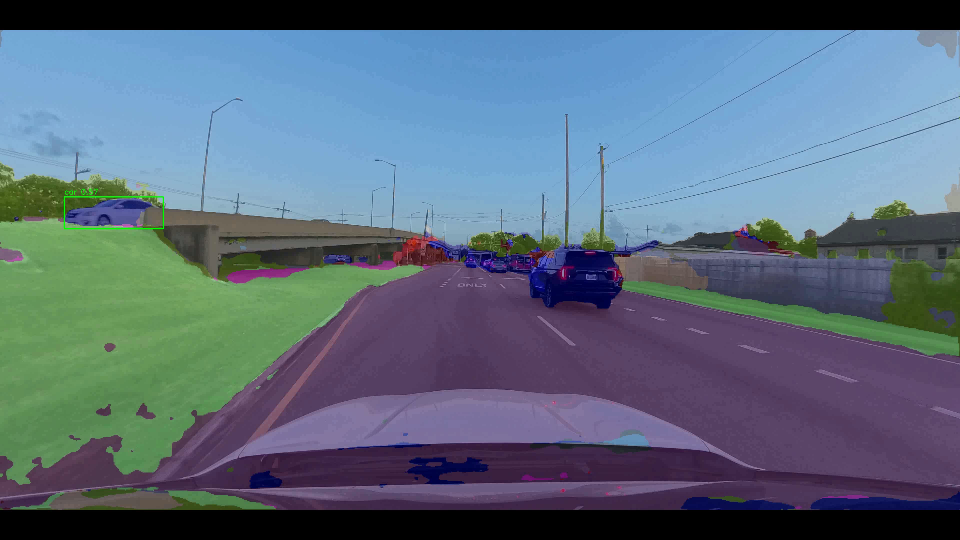


FFprobe:
[STREAM]
index=0
codec_name=mpeg4
codec_long_name=MPEG-4 part 2
profile=Simple Profile
codec_type=video
codec_tag_string=mp4v
codec_tag=0x7634706d
width=3840
height=2160
coded_width=3840
coded_height=2160
closed_captions=0
film_grain=0
has_b_frames=0
sample_aspect_ratio=1:1
display_aspect_ratio=16:9
pix_fmt=yuv420p
level=1
color_range=unknown
color_space=unknown
color_transfer=unknown
color_primaries=unknown
chroma_location=left
field_order=unknown
refs=1
quarter_sample=false
divx_packed=false
id=0x1
r_frame_rate=2997/100
avg_frame_rate=2997/100
time_base=1/11988
start_pts=0
start_time=0.000000
duration_ts=614800
duration=51.284618
bit_rate=47336870
max_bit_rate=N/A
bits_per_raw_sample=N/A
nb_frames=1537
nb_read_frames=N/A
nb_read_packets=N/A
extradata_size=47
DISPOSITION:default=1
DISPOSITION:dub=0
DISPOSITION:original=0
DISPOSITION:comment=0
DISPOSITION:lyrics=0
DISPOSITION:karaoke=0
DISPOSITION:forced=0
DISPOSITION:hearing_impaired=0
DISPOSITION:visual_impaired=0
DISPOSITI

In [ ]:

import subprocess

test_cap = cv2.VideoCapture(combined_output_path)

print("Video opened:", test_cap.isOpened())
print("Frame count:", int(test_cap.get(cv2.CAP_PROP_FRAME_COUNT)))
print("FPS:", test_cap.get(cv2.CAP_PROP_FPS))

ret, first_frame = test_cap.read()
print("First frame readable:", ret)

if ret:
    from google.colab.patches import cv2_imshow
    cv2_imshow(cv2.resize(first_frame, (960, 540)))

test_cap.release()

# Verify stream metadata
probe = subprocess.run(
    ["ffprobe", "-v", "error", "-show_streams", combined_output_path],
    capture_output=True,
    text=True
)

print("\nFFprobe:")
print(probe.stdout if probe.stdout else probe.stderr)


In [ ]:
import shutil
import os

drive_output_path = (
    "/content/drive/MyDrive/Road_Segmentation_Models/"
    "combined_road_scene_video_fixed.mp4"
)

shutil.copy2(combined_output_path, drive_output_path)

print("Saved:", os.path.exists(drive_output_path))
print("File size (MB):", round(os.path.getsize(drive_output_path) / (1024**2), 2))

Saved: True
File size (MB): 289.41
